# Phase 4 · 2/3 — Forecasting the KPI with Deep Learning (LSTM / RNN)

**VIGIE · Group BI 5** — Raed Meddeb · Ibrahim Grira · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Integrated Project, ESPRIT School of Business · Supervisors: Aymen Ben Brik and Hela Hammami

---

**Question.** Does a recurrent network forecast next week's number of closures better than a simple rule?

| Step | Content |
|---|---|
| 1 | Protocol: chronological split, sliding windows, normalisation |
| 2 | Reference models: naive, moving average, moving median, ARIMA |
| 3 | LSTM and simple RNN |
| 4 | Comparison over the last 40 weeks (MAE, RMSE) |
| 5 | Error analysis |
| 6 | Forecast of the next 8 weeks |
| 7 | Bonus: a second KPI |

The model code is in `04_machine_learning/src/forecasting.py`; this notebook runs it and comments on the results.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "04_machine_learning" / "src"))
import forecasting
from vigie import config, data, series, style

warnings.filterwarnings("ignore")
style.apply()
C = config.COLORS
n = style.thousands

# The series is rebuilt from the data (not read back from a file): the notebook is self-contained.
df = data.load()
accounts = data.account_grain(df)
raw = series.weekly_series(accounts.loc[accounts["CHURN"] == 1, "ACCT_CLOSE_DATE"])
mass = series.mass_weeks(raw)
serie = series.correct_mass_weeks(raw, mass)
values = serie.to_numpy(dtype=float)
print(f"{len(serie)} weeks, from {serie.index[0]:%d/%m/%Y} to {serie.index[-1]:%d/%m/%Y} — {len(mass)} mass weeks corrected")

202 weeks, from 13/04/2020 to 19/02/2024 — 5 mass weeks corrected


## 1. Evaluation protocol

### 1.1 Chronological split

No random shuffling: the model is trained on the past and evaluated on the future.

,Role,Start,End,Weeks,Share
Training,Learning the weights,13/04/2020,26/12/2022,142,70%
Validation,Early stopping of the training,02/01/2023,15/05/2023,20,10%
Test,Final evaluation (never seen),22/05/2023,19/02/2024,40,20%


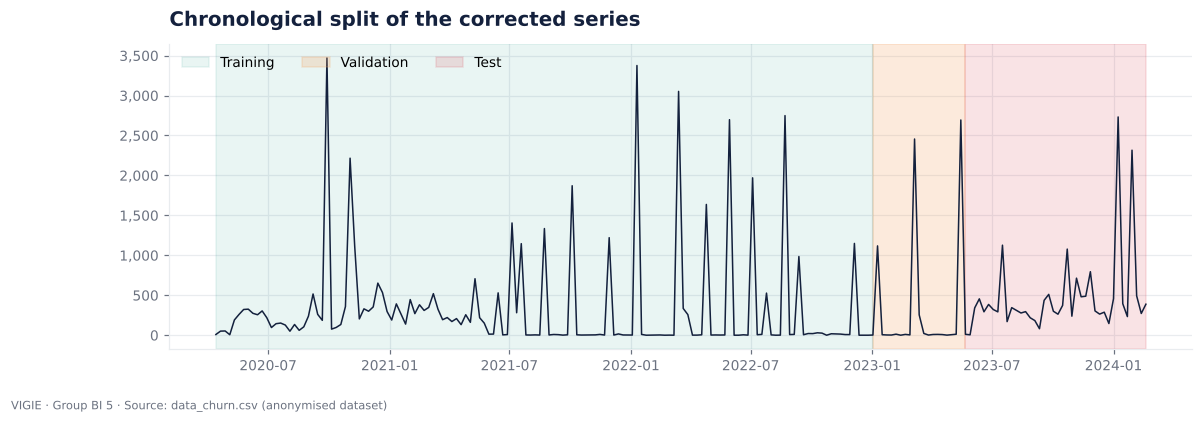

In [2]:
split = forecasting.Split.build(values)
plan = pd.DataFrame({
    "Role": ["Learning the weights", "Early stopping of the training", "Final evaluation (never seen)"],
    "Start": [serie.index[0], serie.index[split.train_end], serie.index[split.validation_end]],
    "End": [serie.index[split.train_end - 1], serie.index[split.validation_end - 1], serie.index[-1]],
    "Weeks": [split.train_end, forecasting.VALIDATION_SIZE, forecasting.TEST_SIZE],
}, index=["Training", "Validation", "Test"])
plan["Share"] = (plan["Weeks"] / split.n).map("{:.0%}".format)
plan["Start"] = plan["Start"].dt.strftime("%d/%m/%Y")
plan["End"] = plan["End"].dt.strftime("%d/%m/%Y")
display(plan)

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(serie.index, serie.values, color=C["ink"], lw=1)
ax.axvspan(serie.index[0], serie.index[split.train_end], color=C["retention"], alpha=0.10, label="Training")
ax.axvspan(serie.index[split.train_end], serie.index[split.validation_end], color=C["amber"], alpha=0.22, label="Validation")
ax.axvspan(serie.index[split.validation_end], serie.index[-1], color=C["churn"], alpha=0.13, label="Test")
ax.yaxis.set_major_formatter(style.thousands)
ax.set_title("Chronological split of the corrected series")
ax.legend(loc="upper left", ncol=3)
style.save(fig, "04_time_split")
plt.show()

### 1.2 Transform and normalisation — with no information leak

1. `log(1 + x)`: brings the spikes back to a scale comparable with the rest (the `+ 1` handles zero weeks).
2. Standardisation with the mean and standard deviation **computed on the training part only**.
   Using the statistics of the whole series would let information from the future into the model.

In [3]:
print(f"Normalisation parameters, computed on the {split.train_end} training weeks:")
print(f"   mean of log(1 + x) = {split.mean:.3f}   |   standard deviation = {split.std:.3f}")
z_test = split.normalise(values[split.validation_end:])
print(f"Check: on the test set, the normalised series has a mean of {z_test.mean():+.2f} (≠ 0, as expected: "
      f"the test set was not used in the computation).")

Normalisation parameters, computed on the 142 training weeks:
   mean of log(1 + x) = 3.803   |   standard deviation = 2.387
Check: on the test set, the normalised series has a mean of +0.82 (≠ 0, as expected: the test set was not used in the computation).


### 1.3 Sliding windows

The network receives the **last 8 weeks** and must forecast **the next one**. The window slides one week at a time.

In [4]:
X, y = series.windows(split.normalise(values), forecasting.WINDOW)
target = np.arange(forecasting.WINDOW, split.n)
window_counts = pd.Series({
    "Training windows": int((target < split.train_end).sum()),
    "Validation windows": int(((target >= split.train_end) & (target < split.validation_end)).sum()),
    "Test windows": int((target >= split.validation_end).sum()),
}, name="Count")
display(window_counts.to_frame())
print(f"Shape of X: {X.shape}  →  (windows, {forecasting.WINDOW} weeks)   |   Shape of y: {y.shape}")
print("A test window contains weeks from before the test period: this is normal, they are values already "
      "observed at the time of the forecast.")

,Count
Training windows,134
Validation windows,20
Test windows,40


Shape of X: (194, 8)  →  (windows, 8 weeks)   |   Shape of y: (194,)
A test window contains weeks from before the test period: this is normal, they are values already observed at the time of the forecast.


**"One-step-ahead" forecast.** For each week of the test set, every model — networks and references — forecasts
from the values actually observed up to the previous week. This is how it would run in operation: every Monday,
we forecast the week that begins.

## 2. Reference models

A neural network is only worth it if it beats rules that fit in one line.

| Reference | Forecast for week *t* |
|---|---|
| **Naive** | the value of week *t − 1* |
| **4-week moving average** | the mean of the last 4 weeks |
| **8-week moving median** | the median of the last 8 weeks — robust to spikes |
| **ARIMA** | classic statistical model on `log(1 + x)`, order chosen by AIC on the period before the test |

In [5]:
result = forecasting.evaluate_kpi(serie)        # also trains the networks (≈ 1 minute)
lstm_model = result.pop("_lstm_model")
comparison = pd.DataFrame(result["comparison"]).set_index("Model")
print("ARIMA order chosen by AIC:", tuple(result["arima_order"]))
display(comparison.loc[comparison["Type"] == "Reference", ["MAE", "RMSE"]].round(1))

ARIMA order chosen by AIC: (2, 1, 2)


,MAE,RMSE
Model,,
Naive (last value),478.3,859.5
4-week moving average,373.0,575.3
8-week moving median,272.4,549.8
"ARIMA(2, 1, 2)",334.7,576.7


## 3. Recurrent networks: LSTM and simple RNN

**Architecture** — deliberately small, because only about 130 training windows are available:

```
Input (8 weeks, 1 variable)  →  LSTM or simple RNN (32 units)  →  Dense (1)  →  next week
```

| Choice | Value | Why |
|---|---|---|
| Window | 8 weeks | covers the useful lags of the PACF and the 5-week rhythm |
| Units | 32, a single layer | little data: a bigger network would learn the noise |
| Loss function | absolute error (MAE) | less sensitive to spikes than squared error |
| Optimiser | Adam, step 0.005 | standard setting |
| Early stopping | patience of 30 epochs on the validation set | avoids over-fitting, restores the best weights |
| Seeds | 42, 7, 123 | the initialisation is random: we report the mean and the spread over 3 trainings |

In [6]:
sizes = pd.DataFrame({
    "Layers": ["LSTM (32) → Dense (1)", "Simple RNN (32) → Dense (1)"],
    "Parameters to learn": [forecasting.build_network(t).count_params() for t in ("lstm", "rnn")],
    "Training windows": [int(window_counts["Training windows"])] * 2,
}, index=["LSTM", "Simple RNN"])
display(sizes)

,Layers,Parameters to learn,Training windows
LSTM,LSTM (32) → Dense (1),4385,134
Simple RNN,Simple RNN (32) → Dense (1),1121,134


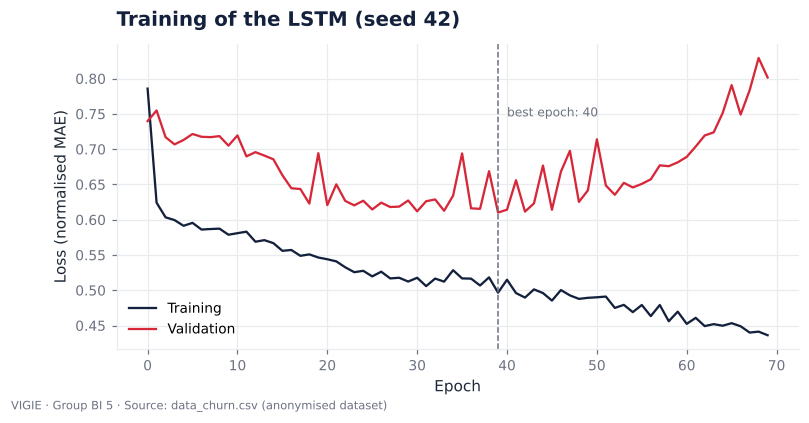

Epochs run before early stopping: {'LSTM': [70, 60, 64], 'Simple RNN': [33, 56, 33]}


In [7]:
hist = result["lstm_history"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(hist["loss"], color=C["ink"], label="Training")
ax.plot(hist["val_loss"], color=C["churn"], label="Validation")
best_epoch = int(np.argmin(hist["val_loss"]))
ax.axvline(best_epoch, color=C["grey"], ls="--", lw=1)
ax.text(best_epoch + 1, max(hist["loss"]) * 0.95, f"best epoch: {best_epoch + 1}", fontsize=8, color=C["grey"])
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (normalised MAE)")
ax.set_title("Training of the LSTM (seed 42)")
ax.legend()
style.save(fig, "04_lstm_training")
plt.show()
print("Epochs run before early stopping:", {m: comparison.loc[m, "Epochs"] for m in ["LSTM", "Simple RNN"]})

The LSTM has about four times as many parameters as the simple RNN (its "gates" let it keep or forget a piece of
information over several weeks). In both cases there are far more parameters than training windows: **early
stopping** is essential, and it does kick in after 60 to 70 epochs for the LSTM, 33 to 56 for the RNN.

## 4. Comparison over the last 40 weeks

**Metrics.** MAE (mean absolute error, in number of closures) and RMSE (which penalises large errors more).
**MAPE is not used**: it is not defined when the actual value is zero.

In [8]:
naive = comparison.loc["Naive (last value)"]
table = comparison[["Type", "MAE", "RMSE"]].copy()
table["MAE vs naive"] = table["MAE"] / naive["MAE"] - 1
table["RMSE vs naive"] = table["RMSE"] / naive["RMSE"] - 1
table["MAE spread (3 seeds)"] = comparison.get("MAE std")
table = table.sort_values("MAE")
display(table.style.format({"MAE": "{:.1f}", "RMSE": "{:.1f}", "MAE vs naive": "{:+.0%}", "RMSE vs naive": "{:+.0%}",
                            "MAE spread (3 seeds)": lambda v: "—" if pd.isna(v) else f"± {v:.1f}"}))
print(table.round(3).to_string())

,Type,MAE,RMSE,MAE vs naive,RMSE vs naive,MAE spread (3 seeds)
Model,,,,,,
8-week moving median,Reference,272.4,549.8,-43%,-36%,—
LSTM,Deep Learning,287.2,577.2,-40%,-33%,± 6.4
Simple RNN,Deep Learning,323.6,607.7,-32%,-29%,± 9.3
"ARIMA(2, 1, 2)",Reference,334.7,576.7,-30%,-33%,—
4-week moving average,Reference,373.0,575.3,-22%,-33%,—
Naive (last value),Reference,478.3,859.5,+0%,+0%,—


                                Type      MAE     RMSE  MAE vs naive  RMSE vs naive  MAE spread (3 seeds)
Model                                                                                                    
8-week moving median       Reference  272.400  549.767        -0.430         -0.360                   NaN
LSTM                   Deep Learning  287.185  577.250        -0.400         -0.328                 6.423
Simple RNN             Deep Learning  323.605  607.651        -0.323         -0.293                 9.285
ARIMA(2, 1, 2)             Reference  334.709  576.710        -0.300         -0.329                   NaN
4-week moving average      Reference  373.031  575.338        -0.220         -0.331                   NaN
Naive (last value)         Reference  478.300  859.478         0.000          0.000                   NaN


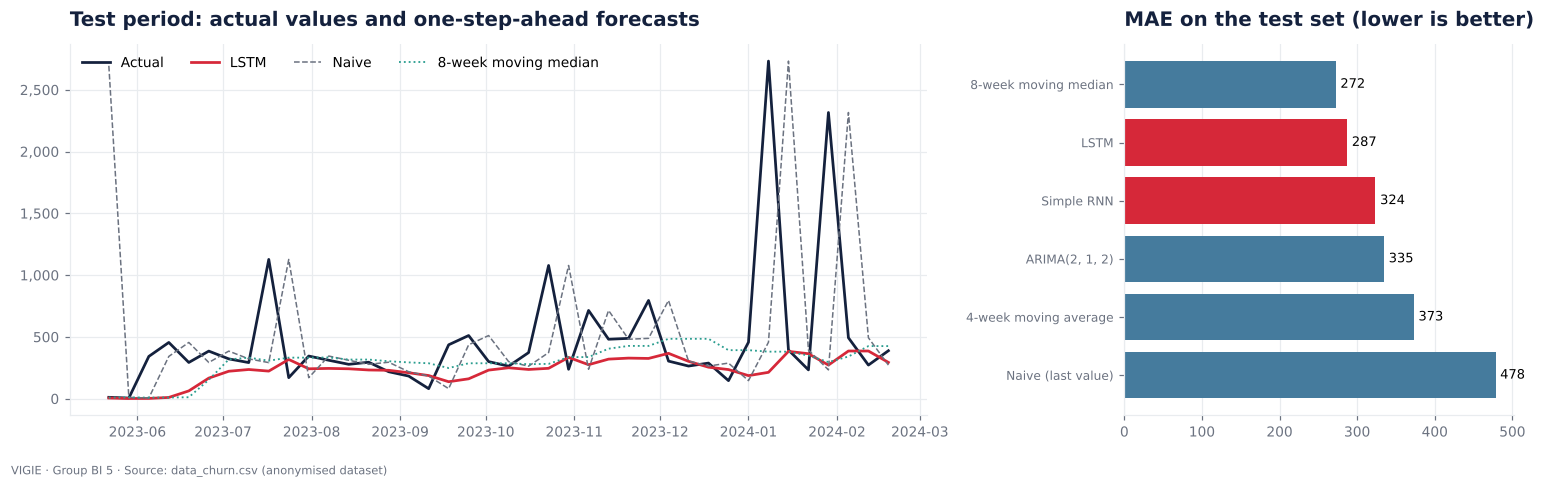

In [9]:
test_weeks = pd.to_datetime(result["test"]["weeks"])
actual = np.array(result["test"]["actual"])
fc = result["test"]["forecasts"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(test_weeks, actual, color=C["ink"], lw=1.8, label="Actual")
axes[0].plot(test_weeks, fc["LSTM"], color=C["churn"], lw=1.8, label="LSTM")
axes[0].plot(test_weeks, fc["Naive (last value)"], color=C["grey"], lw=1, ls="--", label="Naive")
axes[0].plot(test_weeks, fc["8-week moving median"], color=C["retention"], lw=1.2, ls=":", label="8-week moving median")
axes[0].yaxis.set_major_formatter(style.thousands)
axes[0].set_title("Test period: actual values and one-step-ahead forecasts")
axes[0].legend(ncol=4, loc="upper left")
order = table.index[::-1]
colors = [C["churn"] if comparison.loc[m, "Type"] == "Deep Learning" else C["sky"] for m in order]
axes[1].barh(order, table.loc[order, "MAE"], color=colors)
for i, m in enumerate(order):
    axes[1].text(table.loc[m, "MAE"] + 6, i, f"{table.loc[m, 'MAE']:.0f}", va="center", fontsize=8.5)
axes[1].set_title("MAE on the test set (lower is better)")
axes[1].grid(axis="y", visible=False)
axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout()
style.save(fig, "04_lstm_vs_references")
plt.show()

**Reading — does the LSTM prove its worth?**

* **Against the naive forecast: yes, clearly.** The LSTM cuts the MAE by 40% (287 against 478 closures) and the
  RMSE by 33%. Repeating the last value is a poor strategy on such an irregular series.
* **Against the other models: it is near the top of the table.** It does better in MAE than the simple RNN (324),
  ARIMA (335) and the moving average (373). In RMSE, the LSTM, ARIMA and the moving average are tied (≈ 576).
* **Against the best simple rule: no.** The **8-week moving median** does slightly better (MAE 272, RMSE 550).
  The gap in MAE (15 closures) exceeds the spread of the LSTM across seeds (± 6): it is small, but it is real.

**Honest conclusion.** The LSTM brings a large gain over the naive reference, but it does **not improve** on a
moving median, which fits in one line. Three reasons explain it:

1. **Little data**: 134 training windows for 4,385 parameters.
2. **Regime change**: the model learns mostly on regimes 1 and 2 (including two years of batch processing) and
   is tested on regime 3, which is higher. The normalised series has a mean of +0.82 on the test set instead of 0.
3. **Unpredictable spikes**: they do not depend on the past of the series; a median ignores them by construction,
   which is the best answer here.

This result is in line with what the project guide announced: *with about 200 points, the LSTM may not win, and
that result is acceptable if it is demonstrated.*

## 5. Error analysis of the LSTM

,Weeks,LSTM MAE,Naive MAE,8-week moving median MAE,LSTM mean error (bias)
"Ordinary weeks (< 1,000)",36,141.8,367.6,136.3,96.0
"Spike weeks (≥ 1,000)",4,1574.8,1474.5,1496.9,1574.8
Whole test set,40,285.1,478.3,272.4,243.9


Share of the total absolute error due to the 4 spike weeks: 55%


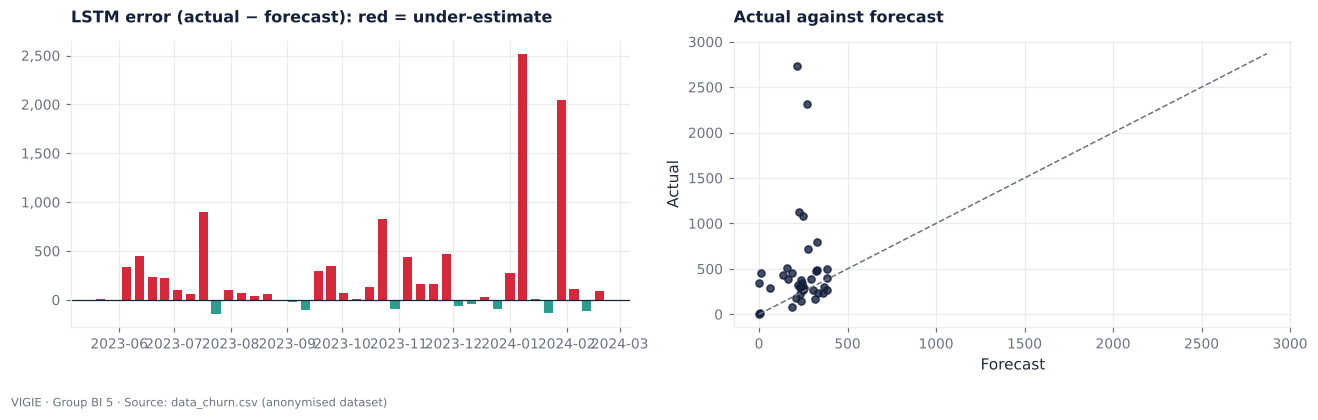

In [10]:
error = actual - np.array(fc["LSTM"])
spikes = actual >= 1000
analysis = pd.DataFrame({
    "Weeks": [int((~spikes).sum()), int(spikes.sum()), len(actual)],
    "LSTM MAE": [np.abs(error[~spikes]).mean(), np.abs(error[spikes]).mean(), np.abs(error).mean()],
    "Naive MAE": [np.abs(actual - np.array(fc["Naive (last value)"]))[m].mean() for m in (~spikes, spikes, slice(None))],
    "8-week moving median MAE": [np.abs(actual - np.array(fc["8-week moving median"]))[m].mean() for m in (~spikes, spikes, slice(None))],
    "LSTM mean error (bias)": [error[~spikes].mean(), error[spikes].mean(), error.mean()],
}, index=["Ordinary weeks (< 1,000)", "Spike weeks (≥ 1,000)", "Whole test set"])
display(analysis.round(1))
print(f"Share of the total absolute error due to the {int(spikes.sum())} spike weeks: {np.abs(error[spikes]).sum() / np.abs(error).sum():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(test_weeks, error, width=5, color=[C["churn"] if e > 0 else C["retention"] for e in error])
axes[0].axhline(0, color=C["ink"], lw=0.8)
axes[0].set_title("LSTM error (actual − forecast): red = under-estimate", fontsize=10.5)
axes[0].yaxis.set_major_formatter(style.thousands)
axes[1].scatter(fc["LSTM"], actual, color=C["ink"], s=22, alpha=0.8)
lim = max(actual.max(), max(fc["LSTM"])) * 1.05
axes[1].plot([0, lim], [0, lim], color=C["grey"], ls="--", lw=1)
axes[1].set_xlabel("Forecast")
axes[1].set_ylabel("Actual")
axes[1].set_title("Actual against forecast", fontsize=10.5)
fig.tight_layout()
style.save(fig, "04_lstm_errors")
plt.show()

**Reading — where the LSTM goes wrong.**

* **Four spike weeks concentrate 55% of the error.** On those weeks no model does better than the others: the
  error is about 1,500 closures for all of them.
* **On the 36 ordinary weeks the LSTM error falls to 142 closures**, against 368 for the naive forecast — 2.6
  times less — and 136 for the moving median.
* **The LSTM under-estimates**: its mean error is positive (+96 on ordinary weeks). This is the trace of the
  regime change: it learnt a lower level than that of the test period.

## 6. Forecast of the next 8 weeks

Beyond the last observed week, the forecast is **recursive**: each forecast week is fed back as an input to
forecast the next one. Uncertainty therefore grows with the horizon.

The interval shown is **empirical**: it uses the 10% and 90% quantiles of the gap between actual and forecast
values observed over the test period. It gives an order of magnitude of the uncertainty, not a statistical guarantee.

,LSTM forecast,Lower bound (10%),Upper bound (90%)
Week starting,,,
26/02/2024,276,193,1468
04/03/2024,245,171,1306
11/03/2024,223,156,1187
18/03/2024,205,143,1089
25/03/2024,190,132,1010
01/04/2024,179,125,953
08/04/2024,170,118,904
15/04/2024,162,113,861


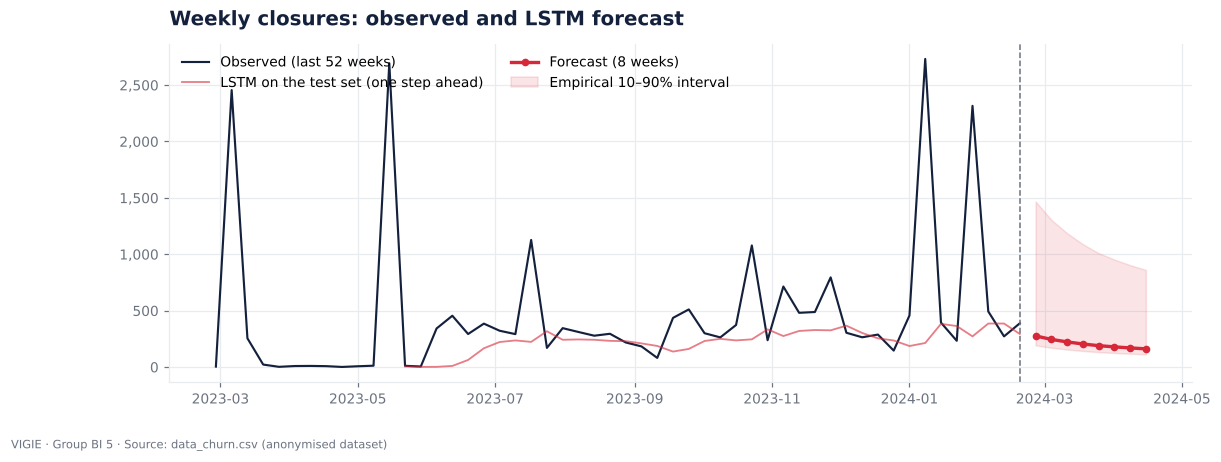

In [11]:
future = pd.DataFrame(result["future"]).set_index("weeks")
future.index = pd.to_datetime(future.index).strftime("%d/%m/%Y")
future.index.name = "Week starting"
future.columns = ["LSTM forecast", "Lower bound (10%)", "Upper bound (90%)"]
display(future.round(0).astype(int))

future_weeks = pd.to_datetime(result["future"]["weeks"])
fig, ax = plt.subplots(figsize=(12, 4))
recent = serie.iloc[-52:]
ax.plot(recent.index, recent.values, color=C["ink"], lw=1.4, label="Observed (last 52 weeks)")
ax.plot(test_weeks, fc["LSTM"], color=C["churn"], lw=1.2, alpha=0.6, label="LSTM on the test set (one step ahead)")
ax.plot(future_weeks, result["future"]["forecast"], color=C["churn"], lw=2.2, marker="o", ms=4, label="Forecast (8 weeks)")
ax.fill_between(future_weeks, result["future"]["low"], result["future"]["high"], color=C["churn"], alpha=0.12, label="Empirical 10–90% interval")
ax.axvline(serie.index[-1], color=C["grey"], ls="--", lw=1)
ax.yaxis.set_major_formatter(style.thousands)
ax.set_title("Weekly closures: observed and LSTM forecast")
ax.legend(loc="upper left", ncol=2)
style.save(fig, "04_future_forecast")
plt.show()

**Reading.** The forecast starts at about 280 closures and then **declines week after week**. This does not
announce a drop in churn: in recursive mode the network feeds on its own forecasts and drifts back towards the
average level it learnt. The forecast is therefore useful mostly for **the first one or two weeks**; beyond that
it must be recomputed every week with the new observations. The upper bound, very wide, is a reminder that a spike
remains possible at any time.

## 7. Bonus — a second KPI: customers lost per week

**Definition.** Number of customers whose *last* account closes during the week: this is the moment the customer
is definitely lost. The first KPI counts accounts, this one counts **customers**.

The same approach is applied without changing anything in the code: same rule for mass operations, same split,
same models.

In [12]:
customers = data.customer_grain(df, accounts)
raw_customers = series.weekly_series(customers.loc[customers["CHURN"] == 1, "CHURN_DATE"])
mass_customers = series.mass_weeks(raw_customers)
serie_customers = series.correct_mass_weeks(raw_customers, mass_customers)
print(f"{len(serie_customers)} weeks · {n(raw_customers.sum())} customers lost · "
      f"{len(mass_customers)} mass weeks ({raw_customers[mass_customers].sum() / raw_customers.sum():.1%} of the volume) · "
      f"{int((serie_customers == 0).sum())} zero weeks")

result_customers = forecasting.evaluate_kpi(serie_customers)
result_customers.pop("_lstm_model")
comparison_customers = pd.DataFrame(result_customers["comparison"]).set_index("Model")
naive_c = comparison_customers.loc["Naive (last value)"]
table_customers = comparison_customers[["Type", "MAE", "RMSE"]].copy()
table_customers["MAE vs naive"] = table_customers["MAE"] / naive_c["MAE"] - 1
table_customers["RMSE vs naive"] = table_customers["RMSE"] / naive_c["RMSE"] - 1
table_customers = table_customers.sort_values("MAE")
print(table_customers.round(3).to_string())

202 weeks · 117,345 customers lost · 4 mass weeks (55.2% of the volume) · 13 zero weeks


                                Type      MAE     RMSE  MAE vs naive  RMSE vs naive
Model                                                                              
LSTM                   Deep Learning  124.501  220.184        -0.452         -0.521
8-week moving median       Reference  133.300  216.366        -0.413         -0.529
Simple RNN             Deep Learning  143.630  232.844        -0.368         -0.493
ARIMA(2, 1, 2)             Reference  159.884  248.945        -0.296         -0.458
4-week moving average      Reference  196.419  275.980        -0.135         -0.399
Naive (last value)         Reference  227.200  459.468         0.000          0.000


**Reading — second KPI.** The same approach leads to similar conclusions, with a nuance in favour of the
network: on customers lost, the **LSTM has the best MAE** (125 against 133 for the moving median) and the second
best RMSE (220 against 216). It cuts the MAE by 45% compared with the naive forecast. The "customers" series is a
little more regular than the "accounts" series, which benefits the learnt model.

## Summary

| KPI | Best MAE | LSTM vs naive (MAE) | LSTM vs best simple reference (MAE) |
|---|---|---|---|
| Account closures per week | 8-week moving median (272) | −40% | +5% (287 against 272) |
| Customers lost per week | **LSTM (125)** | −45% | −7% (125 against 133) |

**What we keep for the application.** The forecast displayed is that of the **LSTM**, as requested, together with
the full comparison table: the user sees the forecast *and* how reliable it is compared with simple rules. In
operation we would recommend following the LSTM and the moving median side by side, and re-training the network
as the current regime gets longer.

In [13]:
# Saving the results (weekly aggregates and metrics: no individual data).
def clean(r: dict) -> dict:
    return {k: v for k, v in r.items() if k != "lstm_history"}


def without_epochs(rows: list[dict]) -> list[dict]:
    return [{k: v for k, v in row.items() if k != "Epochs"} for row in rows]


config.ML_RESULTS.mkdir(parents=True, exist_ok=True)
(config.ML_RESULTS / "kpi_forecast.json").write_text(json.dumps({
    "source_sha256": data.fingerprint()["sha256"],
    "weekly_closures": clean(result),
    "weekly_customers_lost": clean(result_customers),
}, ensure_ascii=False, indent=1), encoding="utf-8")

# Artefact read by the application: the series, the forecast and the model comparison.
config.APP_ARTIFACTS.mkdir(parents=True, exist_ok=True)
(config.APP_ARTIFACTS / "kpi_forecast.json").write_text(json.dumps({
    "kpi": "Weekly number of account closures",
    "date_note": "Dates shifted by the anonymisation: read durations and trends, not a real calendar.",
    "history": {"weeks": [str(s.date()) for s in serie.index], "raw": [int(v) for v in raw.values],
                "corrected": [int(v) for v in serie.values], "mass_weeks": [str(s.date()) for s in mass]},
    "split": result["split"],
    "test": result["test"],
    "future": result["future"],
    "comparison": without_epochs(result["comparison"]),
    "second_kpi": {"name": "Customers lost per week", "comparison": without_epochs(result_customers["comparison"])},
}, ensure_ascii=False, indent=1), encoding="utf-8")

# The trained model stays outside the repository (git-ignored folder).
config.MODELS.mkdir(parents=True, exist_ok=True)
lstm_model.save(config.MODELS / "lstm_weekly_closures.keras")
print("Results : 04_machine_learning/results/kpi_forecast.json")
print("Artefact: 05_web_app/artifacts/kpi_forecast.json")
print("Model   : 04_machine_learning/models/lstm_weekly_closures.keras (outside the repository)")

Results : 04_machine_learning/results/kpi_forecast.json
Artefact: 05_web_app/artifacts/kpi_forecast.json
Model   : 04_machine_learning/models/lstm_weekly_closures.keras (outside the repository)
